# 🦟 VectorIA
## Análisis Exploratorio de Datos (EDA)
### Dataset 6: Dengue nacional y clima — LSTM

**Proyecto:** VectorIA — Asistente Inteligente para la Vigilancia del Dengue en Costa Rica  
**Módulo:** RNN/LSTM — Predicción nacional de casos de dengue  
**Archivo:** `vectoria_dengue_nacional_real.csv`  
**Fuente de casos:** OPS/PAHO a través de OpenDengue  
**Fuente climática:** NASA POWER (agregación nacional, según el material del profesor)  
**Cobertura:** 574 semanas epidemiológicas, 2014–2024.

---

### Objetivo

Examinar calidad, cobertura, evolución temporal, estacionalidad y relación entre clima y casos semanales; investigar rezagos climáticos y preparar criterios de exploración para una LSTM que pronostique **las siguientes cuatro semanas**. **Este notebook no entrena modelos ni genera pronósticos para 2025–2026.**

**Criterio:** los datos originales se conservan sin modificar. Los valores atípicos se examinan antes de cualquier decisión de limpieza; las correlaciones no prueban causalidad.

## 1. Importación de librerías

Se importan una sola vez las herramientas necesarias para cargar, describir y visualizar los datos; no se requieren librerías de aprendizaje profundo.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.2f}".format)

## 2. Carga y exploración inicial del dataset

Se utiliza la ruta exacta de la carpeta facilitada. Se interpretan las fechas y se ordena la serie temporal para evitar problemas al calcular rezagos.

In [2]:
ruta = Path(r"C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\InteligenciaArticial\Proyecto\P2\VectorIA\data\raw\VectorIA-datos")
archivo = ruta / "vectoria_dengue_nacional_real.csv"
datos = pd.read_csv(archivo, parse_dates=["fecha_inicio_semana"])
datos = datos.sort_values("fecha_inicio_semana").reset_index(drop=True)

print("Archivo:", archivo.name)
display(datos.head())
display(datos.tail())

Archivo: vectoria_dengue_nacional_real.csv


,fecha_inicio_semana,anio,semana_epi,provincia,region_climatica,poblacion,casos_dengue,tasa_100k,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
0,2013-12-29,2014,1,Costa Rica,Nacional,5170000,239,4.62,11.00,27.20,19.90,84.90
1,2014-01-05,2014,2,Costa Rica,Nacional,5170000,257,4.97,8.90,27.00,19.70,83.80
2,2014-01-12,2014,3,Costa Rica,Nacional,5170000,184,3.56,4.50,27.10,19.50,81.70
3,2014-01-19,2014,4,Costa Rica,Nacional,5170000,156,3.02,7.70,27.10,19.50,80.00
4,2014-01-26,2014,5,Costa Rica,Nacional,5170000,189,3.66,4.70,27.20,18.70,78.00


,fecha_inicio_semana,anio,semana_epi,provincia,region_climatica,poblacion,casos_dengue,tasa_100k,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
569,2024-11-24,2024,48,Costa Rica,Nacional,5170000,402,7.78,64.90,26.70,21.20,91.40
570,2024-12-01,2024,49,Costa Rica,Nacional,5170000,340,6.58,35.40,26.70,21.10,88.70
571,2024-12-08,2024,50,Costa Rica,Nacional,5170000,312,6.03,14.50,27.60,21.10,85.70
572,2024-12-15,2024,51,Costa Rica,Nacional,5170000,197,3.81,34.10,27.30,20.30,86.70
573,2024-12-22,2024,52,Costa Rica,Nacional,5170000,125,2.42,28.80,26.30,20.90,89.70


## 3. Dimensiones del dataset

Se determina la cantidad de filas y columnas, y se presenta un inventario general de variables.

In [3]:
filas, columnas = datos.shape
print(f"Filas: {filas:,}")
print(f"Columnas: {columnas}")
print("Columnas:", ", ".join(datos.columns))

Filas: 574
Columnas: 12
Columnas: fecha_inicio_semana, anio, semana_epi, provincia, region_climatica, poblacion, casos_dengue, tasa_100k, lluvia_mm, temp_max_c, temp_min_c, humedad_rel_pct


## 4. Identificación de variables y tipos de datos

Se revisan los tipos detectados por Pandas para distinguir fechas, variables numéricas y categóricas.

In [4]:
display(datos.dtypes.rename("Tipo de dato").to_frame())
print("Resumen de memoria y valores no nulos:")
datos.info()

,Tipo de dato
fecha_inicio_semana,datetime64[us]
anio,int64
semana_epi,int64
provincia,str
region_climatica,str
poblacion,int64
casos_dengue,int64
tasa_100k,float64
lluvia_mm,float64
temp_max_c,float64


Resumen de memoria y valores no nulos:
<class 'pandas.DataFrame'>
RangeIndex: 574 entries, 0 to 573
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   fecha_inicio_semana  574 non-null    datetime64[us]
 1   anio                 574 non-null    int64         
 2   semana_epi           574 non-null    int64         
 3   provincia            574 non-null    str           
 4   region_climatica     574 non-null    str           
 5   poblacion            574 non-null    int64         
 6   casos_dengue         574 non-null    int64         
 7   tasa_100k            574 non-null    float64       
 8   lluvia_mm            574 non-null    float64       
 9   temp_max_c           574 non-null    float64       
 10  temp_min_c           574 non-null    float64       
 11  humedad_rel_pct      574 non-null    float64       
dtypes: datetime64[us](1), float64(5), int64(4), str(2)
memory usage:

## 5. Estadísticas descriptivas

Se examinan promedios, dispersión y rangos de las variables numéricas, y se resumen las variables categóricas.

In [5]:
display(datos.describe(include=["number"]).T.round(2))
display(datos.describe(include=["object"]).T)

,count,mean,std,min,25%,50%,75%,max
anio,574.00,2018.99,3.16,2014.00,2016.00,2019.00,2022.00,2024.00
semana_epi,574.00,26.59,15.08,1.00,14.00,27.00,40.00,53.00
poblacion,574.00,5170000.00,0.00,5170000.00,5170000.00,5170000.00,5170000.00,5170000.00
casos_dengue,574.00,268.59,304.17,12.00,71.00,156.00,328.00,1749.00
tasa_100k,574.00,5.20,5.88,0.23,1.37,3.02,6.34,33.83
lluvia_mm,574.00,51.97,57.64,0.00,13.58,38.50,75.40,625.20
temp_max_c,574.00,27.84,1.71,24.40,26.70,27.40,28.70,33.00
temp_min_c,574.00,21.12,0.91,18.40,20.50,21.20,21.80,23.20
humedad_rel_pct,574.00,83.72,7.66,61.80,79.43,86.70,89.30,94.90


C:\Users\andre\AppData\Local\Temp\ipykernel_18368\484346661.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(datos.describe(include=["object"]).T)


,count,unique,top,freq
provincia,574,1,Costa Rica,574
region_climatica,574,1,Nacional,574


## 6. Análisis de valores faltantes

Se cuentan los valores faltantes por variable y sus porcentajes. El profesor indica que esta serie nacional fue entregada sin faltantes.

In [6]:
faltantes = datos.isna().sum()
tabla_faltantes = pd.DataFrame({
    "Variable": faltantes.index,
    "Faltantes": faltantes.to_numpy(),
    "Porcentaje (%)": (faltantes.to_numpy() / len(datos) * 100).round(2),
})
display(tabla_faltantes)
print("Total de celdas faltantes:", int(faltantes.sum()))

,Variable,Faltantes,Porcentaje (%)
0,fecha_inicio_semana,0,0.00
1,anio,0,0.00
2,semana_epi,0,0.00
3,provincia,0,0.00
4,region_climatica,0,0.00
5,poblacion,0,0.00
6,casos_dengue,0,0.00
7,tasa_100k,0,0.00
8,lluvia_mm,0,0.00
9,temp_max_c,0,0.00


Total de celdas faltantes: 0


## 7. Detección de registros duplicados

Se buscan filas duplicadas y duplicaciones de las claves de fecha o año epidemiológico + semana.

In [7]:
repetidos_fila = datos.duplicated().sum()
repetidos_fecha = datos.duplicated(subset=["fecha_inicio_semana"]).sum()
repetidos_semana = datos.duplicated(subset=["anio", "semana_epi"]).sum()
print("Filas idénticas:", repetidos_fila)
print("Fechas iniciales duplicadas:", repetidos_fecha)
print("Combinaciones año-semana duplicadas:", repetidos_semana)

Filas idénticas: 0
Fechas iniciales duplicadas: 0
Combinaciones año-semana duplicadas: 0


## 8. Valores únicos y variables categóricas

Se identifican las categorías disponibles y las columnas que permanecen constantes; el archivo es nacional y no contiene casos por cantón o provincia.

In [8]:
unicos = datos.nunique(dropna=False).sort_values()
display(unicos.rename("Valores distintos").to_frame())
for columna in ["provincia", "region_climatica", "poblacion"]:
    print(f"{columna}: {datos[columna].unique().tolist()}")

,Valores distintos
provincia,1
region_climatica,1
poblacion,1
anio,11
temp_min_c,48
semana_epi,53
temp_max_c,79
humedad_rel_pct,227
casos_dengue,347
tasa_100k,347


provincia: ['Costa Rica']
region_climatica: ['Nacional']
poblacion: [5170000]


## 9. Distribución de variables numéricas

Se observan las distribuciones de casos, tasa y clima. Los histogramas permiten detectar asimetrías y concentraciones.

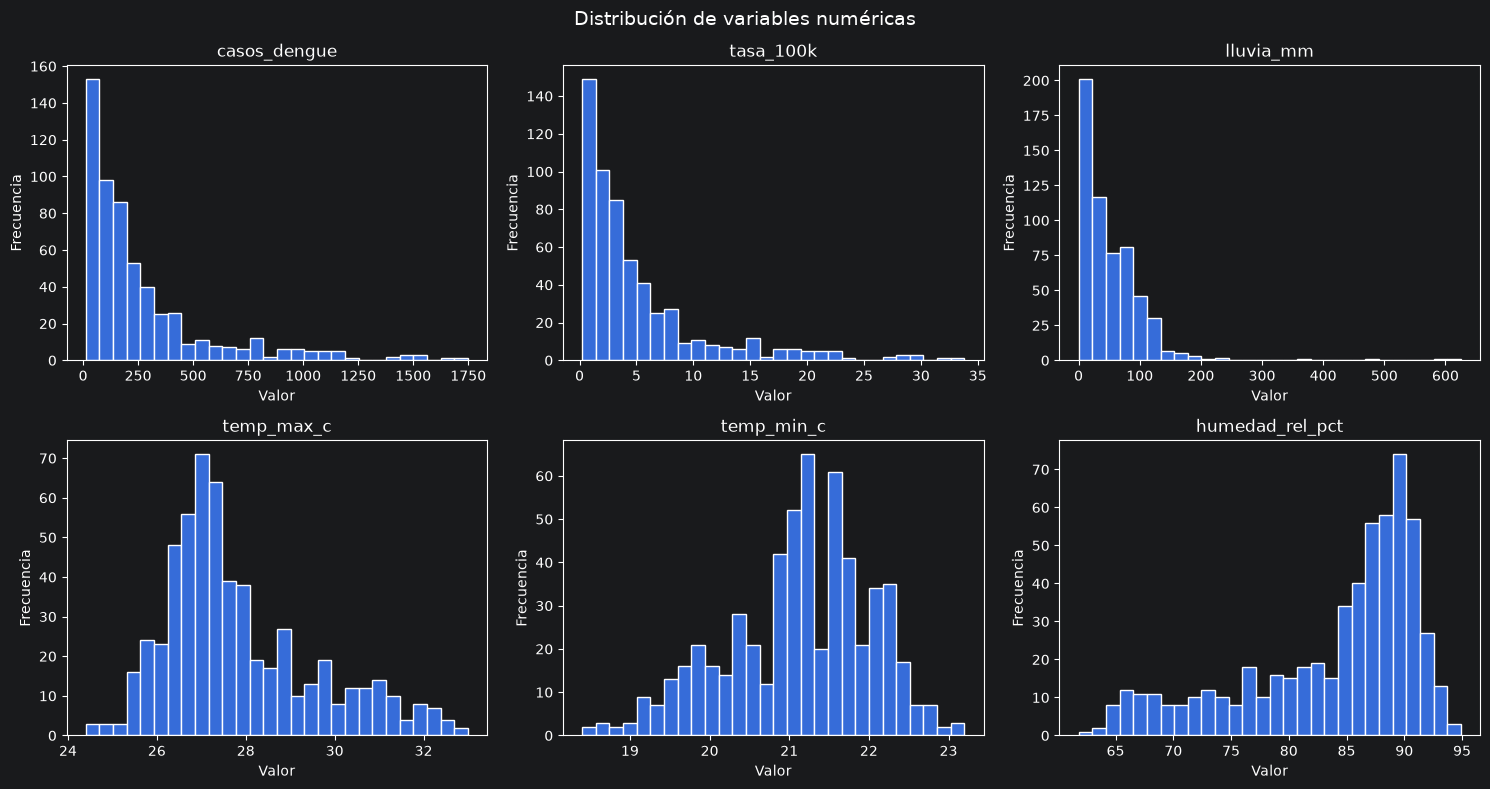

In [9]:
variables_numericas = ["casos_dengue", "tasa_100k", "lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]
fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
for eje, variable in zip(ejes.flat, variables_numericas):
    eje.hist(datos[variable].dropna(), bins=28, edgecolor="white")
    eje.set_title(variable)
    eje.set_xlabel("Valor")
    eje.set_ylabel("Frecuencia")
plt.suptitle("Distribución de variables numéricas", fontsize=14)
plt.tight_layout()
plt.show()

## 10. Detección de valores atípicos (IQR)

Se estima la cantidad de observaciones fuera de los límites intercuartílicos. **No implica que deban eliminarse:** los brotes y las lluvias extremas pueden ser datos reales relevantes.

,Variable,Límite inferior,Límite superior,Atípicos IQR,Porcentaje (%)
0,casos_dengue,-314.50,713.50,57,9.93
1,tasa_100k,-6.09,13.80,57,9.93
2,lluvia_mm,-79.16,168.14,12,2.09
3,temp_max_c,23.70,31.70,21,3.66
4,temp_min_c,18.55,23.75,2,0.35
5,humedad_rel_pct,64.61,104.11,6,1.05


C:\Users\andre\AppData\Local\Temp\ipykernel_18368\743208304.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  eje.boxplot(datos[variable].dropna(), vert=True)
C:\Users\andre\AppData\Local\Temp\ipykernel_18368\743208304.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  eje.boxplot(datos[variable].dropna(), vert=True)
C:\Users\andre\AppData\Local\Temp\ipykernel_18368\743208304.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  eje.boxplot(datos[variable].dropna(), vert=True)


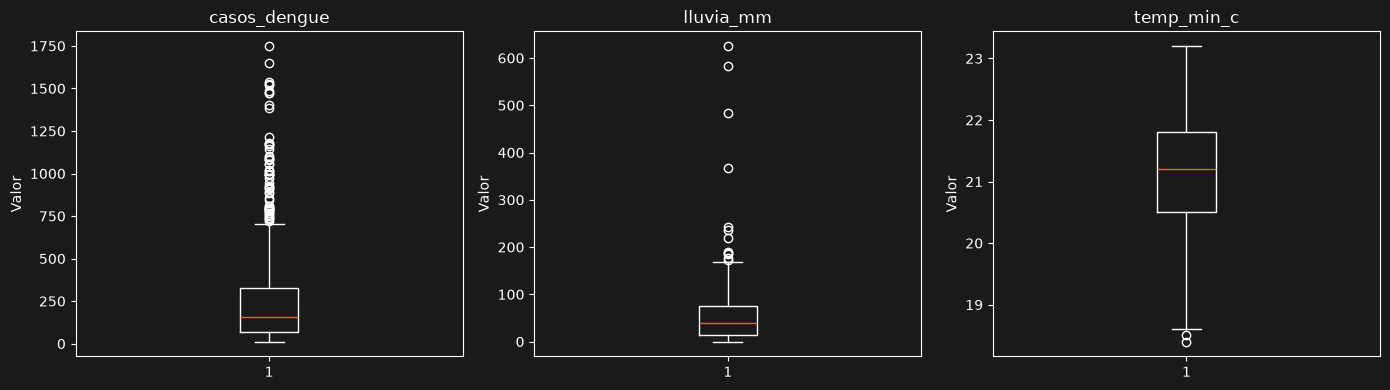

In [10]:
outliers_resumen = []
for variable in variables_numericas:
    serie = datos[variable].dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = int(((serie < inferior) | (serie > superior)).sum())
    outliers_resumen.append({"Variable": variable, "Límite inferior": inferior,
                             "Límite superior": superior, "Atípicos IQR": n_outliers,
                             "Porcentaje (%)": 100 * n_outliers / len(serie)})
df_atipicos = pd.DataFrame(outliers_resumen)
display(df_atipicos.round(2))

fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for eje, variable in zip(ejes, ["casos_dengue", "lluvia_mm", "temp_min_c"]):
    eje.boxplot(datos[variable].dropna(), vert=True)
    eje.set_title(variable)
    eje.set_ylabel("Valor")
plt.tight_layout()
plt.show()

## 11. Validación de rangos y consistencia

Se comprueban valores imposibles, coherencia entre temperaturas y la consistencia aproximada de la tasa de casos por 100.000 habitantes.

In [11]:
validaciones = {
    "Casos negativos": int((datos["casos_dengue"] < 0).sum()),
    "Lluvia negativa": int((datos["lluvia_mm"] < 0).sum()),
    "Humedad fuera de 0–100 %": int((~datos["humedad_rel_pct"].between(0, 100)).sum()),
    "Temperatura máxima menor que mínima": int((datos["temp_max_c"] < datos["temp_min_c"]).sum()),
    "Población no positiva": int((datos["poblacion"] <= 0).sum()),
    "Semana epidemiológica fuera de 1–53": int((~datos["semana_epi"].between(1, 53)).sum()),
}
tasa_calculada = 100_000 * datos["casos_dengue"] / datos["poblacion"]
diferencia_tasa = (tasa_calculada - datos["tasa_100k"]).abs()
validaciones["Diferencias de tasa > 0.01"] = int((diferencia_tasa > 0.01).sum())
display(pd.DataFrame(validaciones.items(), columns=["Validación", "Registros detectados"]))
print("Diferencia máxima de tasa:", round(diferencia_tasa.max(), 4))

,Validación,Registros detectados
0,Casos negativos,0
1,Lluvia negativa,0
2,Humedad fuera de 0–100 %,0
3,Temperatura máxima menor que mínima,0
4,Población no positiva,0
5,Semana epidemiológica fuera de 1–53,0
6,Diferencias de tasa > 0.01,0


Diferencia máxima de tasa: 0.005


## 12. Visualización comparativa inicial

Se comparan las distribuciones mediante diagramas de caja. Las escalas se mantienen separadas porque las variables usan unidades diferentes.

C:\Users\andre\AppData\Local\Temp\ipykernel_18368\1950313046.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  eje.boxplot(datos[variable].dropna(), vert=True)
C:\Users\andre\AppData\Local\Temp\ipykernel_18368\1950313046.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  eje.boxplot(datos[variable].dropna(), vert=True)
C:\Users\andre\AppData\Local\Temp\ipykernel_18368\1950313046.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  eje.boxplot(datos[variable].dropna(), vert=True)
C:\Users\andre\AppData\Local\Temp\ipykernel_18368\1950313046.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use 

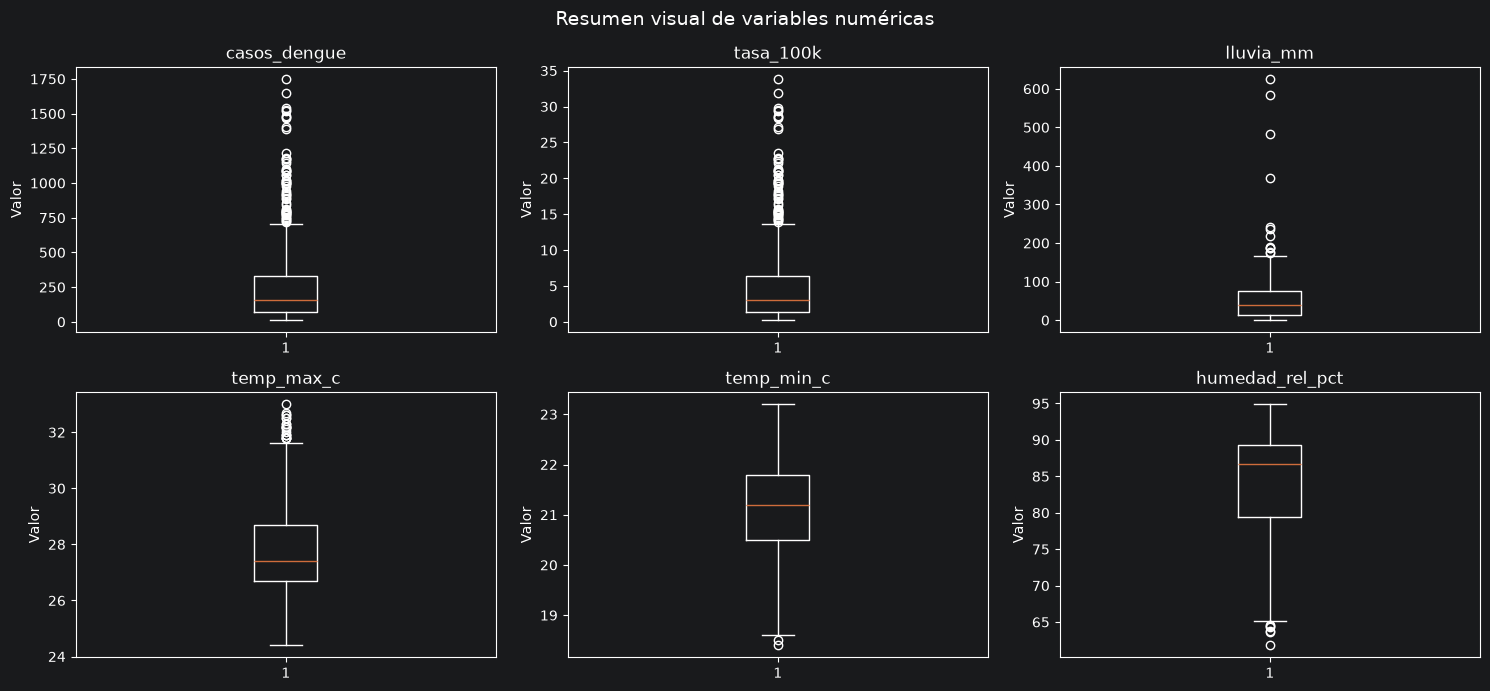

In [12]:
fig, ejes = plt.subplots(2, 3, figsize=(15, 7))
for eje, variable in zip(ejes.flat, variables_numericas):
    eje.boxplot(datos[variable].dropna(), vert=True)
    eje.set_title(variable)
    eje.set_ylabel("Valor")
plt.suptitle("Resumen visual de variables numéricas", fontsize=14)
plt.tight_layout()
plt.show()

## 13. Validación de fechas y semanas epidemiológicas

Se verifica que las semanas comiencen en domingo y que cada año epidemiológico tenga la cobertura esperada. La primera fecha puede pertenecer a diciembre del año civil anterior.

In [13]:
frecuencias = datos["fecha_inicio_semana"].dt.day_name().value_counts()
dias_entre_registros = datos["fecha_inicio_semana"].diff().dt.days.dropna()
conteo_anio_epi = datos.groupby("anio").agg(
    semanas=("semana_epi", "count"),
    semana_min=("semana_epi", "min"),
    semana_max=("semana_epi", "max"),
)
print("Días de inicio de semana:")
display(frecuencias.rename("Cantidad").to_frame())
print("Saltos de días entre registros:")
display(dias_entre_registros.value_counts().sort_index().rename("Frecuencia").to_frame())
print("Semanas registradas por año epidemiológico:")
display(conteo_anio_epi)

Días de inicio de semana:


,Cantidad
fecha_inicio_semana,
Sunday,574


Saltos de días entre registros:


,Frecuencia
fecha_inicio_semana,
7.00,573


Semanas registradas por año epidemiológico:


,semanas,semana_min,semana_max
anio,,,
2014,52,1,52
2015,53,1,53
2016,52,1,52
2017,52,1,52
2018,52,1,52
2019,52,1,52
2020,53,1,53
2021,52,1,52
2022,52,1,52


## 14. Cobertura temporal y detección de semanas faltantes

Se compara el rango registrado con una secuencia semanal de domingos para localizar fechas ausentes, si existen.

In [14]:
fecha_min = datos["fecha_inicio_semana"].min()
fecha_max = datos["fecha_inicio_semana"].max()
calendario_esperado = pd.date_range(fecha_min, fecha_max, freq="W-SUN")
fechas_faltantes = calendario_esperado.difference(pd.DatetimeIndex(datos["fecha_inicio_semana"]))
print("Primera fecha:", fecha_min.date())
print("Última fecha:", fecha_max.date())
print("Semanas esperadas:", len(calendario_esperado))
print("Semanas registradas:", len(datos))
print("Semanas faltantes:", len(fechas_faltantes))
if len(fechas_faltantes):
    display(pd.DataFrame({"Fecha faltante": fechas_faltantes}))

Primera fecha: 2013-12-29
Última fecha: 2024-12-22
Semanas esperadas: 574
Semanas registradas: 574
Semanas faltantes: 0


## 15. Evolución semanal de casos de dengue

Se visualiza la serie de casos y una media móvil de 13 semanas para distinguir fluctuaciones semanales y tendencias generales.

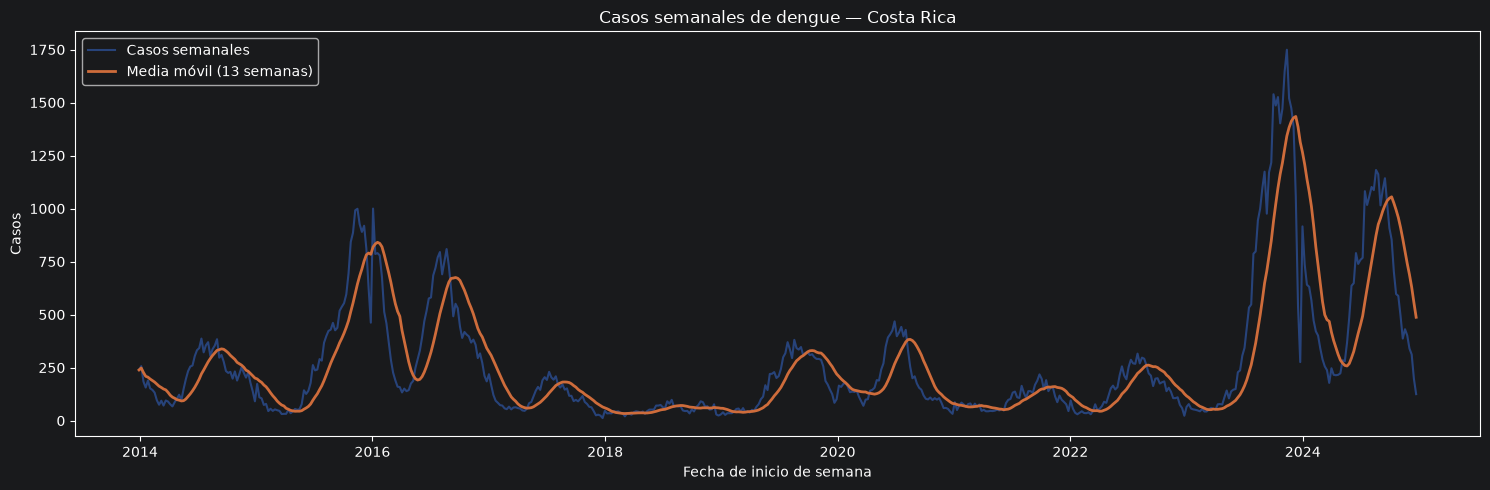

In [15]:
datos["media_movil_13"] = datos["casos_dengue"].rolling(window=13, min_periods=1).mean()
plt.figure(figsize=(15, 5))
plt.plot(datos["fecha_inicio_semana"], datos["casos_dengue"], alpha=0.5, label="Casos semanales")
plt.plot(datos["fecha_inicio_semana"], datos["media_movil_13"], linewidth=2, label="Media móvil (13 semanas)")
plt.title("Casos semanales de dengue — Costa Rica")
plt.xlabel("Fecha de inicio de semana")
plt.ylabel("Casos")
plt.legend()
plt.tight_layout()
plt.show()

## 16. Distribución anual de casos

Se suman los casos por **año epidemiológico** y se identifican períodos de mayor incidencia. Los años 2016, 2023 y 2024 se mencionan como brotes en el material del profesor.

,anio,Casos anuales
0,2014,11049
1,2015,17485
2,2016,23319
3,2017,5561
4,2018,2735
5,2019,9400
6,2020,10056
7,2021,5174
8,2022,7485
9,2023,30649


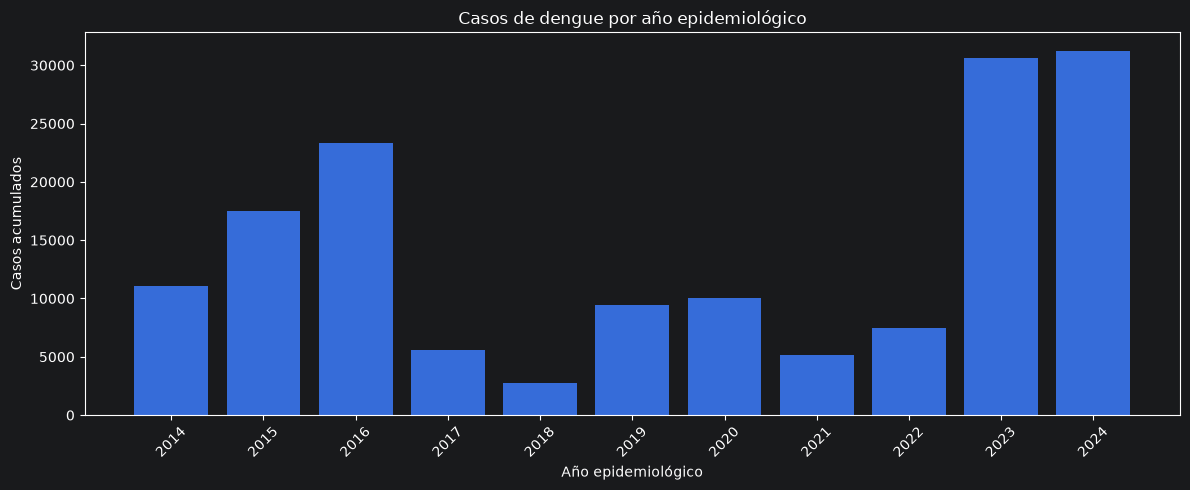

In [16]:
casos_anuales = datos.groupby("anio", as_index=False)["casos_dengue"].sum()
casos_anuales = casos_anuales.rename(columns={"casos_dengue": "Casos anuales"})
display(casos_anuales)
plt.figure(figsize=(12, 5))
plt.bar(casos_anuales["anio"].astype(str), casos_anuales["Casos anuales"])
plt.title("Casos de dengue por año epidemiológico")
plt.xlabel("Año epidemiológico")
plt.ylabel("Casos acumulados")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 17. Picos semanales y años epidémicos

Se identifican las semanas con más casos y se observan los picos de la serie. Un valor extremo durante un brote no debe tratarse automáticamente como un error.

In [17]:
semanas_pico = datos.nlargest(12, "casos_dengue")[["fecha_inicio_semana", "anio", "semana_epi", "casos_dengue"]]
display(semanas_pico)
print("Años con más casos acumulados:")
display(casos_anuales.nlargest(5, "Casos anuales"))

,fecha_inicio_semana,anio,semana_epi,casos_dengue
515,2023-11-12,2023,46,1749
514,2023-11-05,2023,45,1647
509,2023-10-01,2023,40,1539
511,2023-10-15,2023,42,1526
516,2023-11-19,2023,47,1520
510,2023-10-08,2023,41,1486
517,2023-11-26,2023,48,1473
513,2023-10-29,2023,44,1471
512,2023-10-22,2023,43,1402
518,2023-12-03,2023,49,1388


Años con más casos acumulados:


,anio,Casos anuales
10,2024,31259
9,2023,30649
2,2016,23319
1,2015,17485
0,2014,11049


## 18. Análisis de estacionalidad

Se comparan promedio y mediana de casos por semana epidemiológica y por mes de la fecha inicial. Los años de 53 semanas pueden tener menos observaciones en la semana 53.

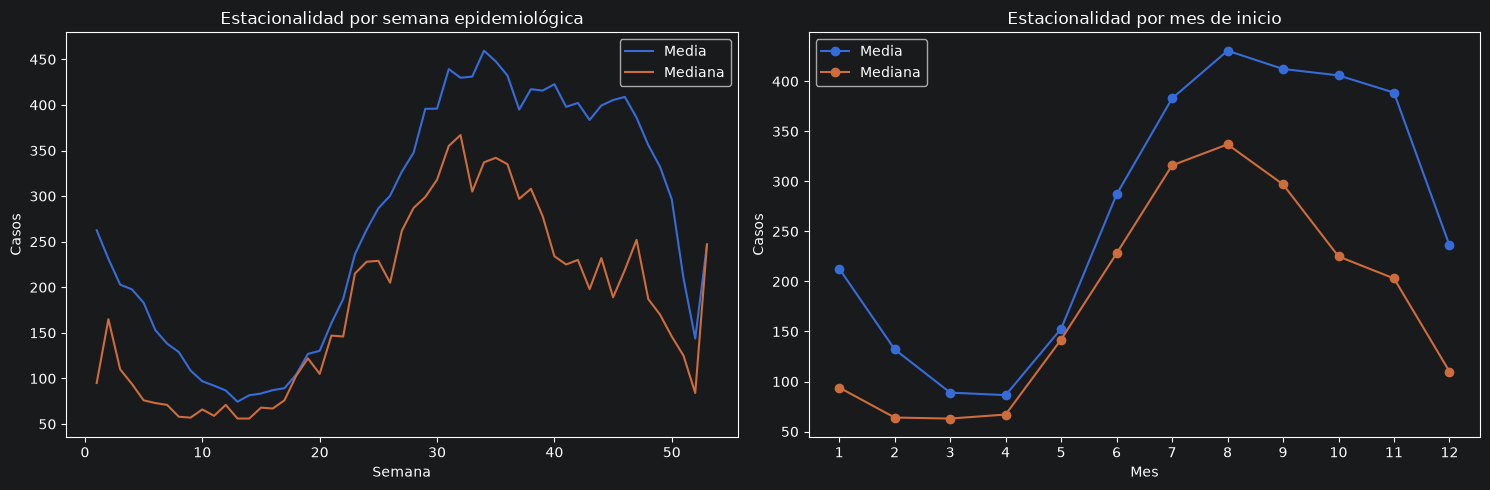

,mean,median,count
semana_epi,,,
49,332.18,170.00,11
50,296.45,146.00,11
51,209.73,125.00,11
52,143.73,84.00,11
53,247.00,247.00,2


In [18]:
estacional_semana = datos.groupby("semana_epi")["casos_dengue"].agg(["mean", "median", "count"])
datos["mes_calendario"] = datos["fecha_inicio_semana"].dt.month
estacional_mes = datos.groupby("mes_calendario")["casos_dengue"].agg(["mean", "median", "count"])
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
ejes[0].plot(estacional_semana.index, estacional_semana["mean"], label="Media")
ejes[0].plot(estacional_semana.index, estacional_semana["median"], label="Mediana")
ejes[0].set(title="Estacionalidad por semana epidemiológica", xlabel="Semana", ylabel="Casos")
ejes[0].legend()
ejes[1].plot(estacional_mes.index, estacional_mes["mean"], marker="o", label="Media")
ejes[1].plot(estacional_mes.index, estacional_mes["median"], marker="o", label="Mediana")
ejes[1].set(title="Estacionalidad por mes de inicio", xlabel="Mes", ylabel="Casos")
ejes[1].set_xticks(range(1, 13))
ejes[1].legend()
plt.tight_layout()
plt.show()
display(estacional_semana.tail(5).round(2))

## 19. Comportamiento semanal de la lluvia

Se analiza la distribución y la evolución de la precipitación semanal para reconocer temporadas húmedas y semanas extremas.

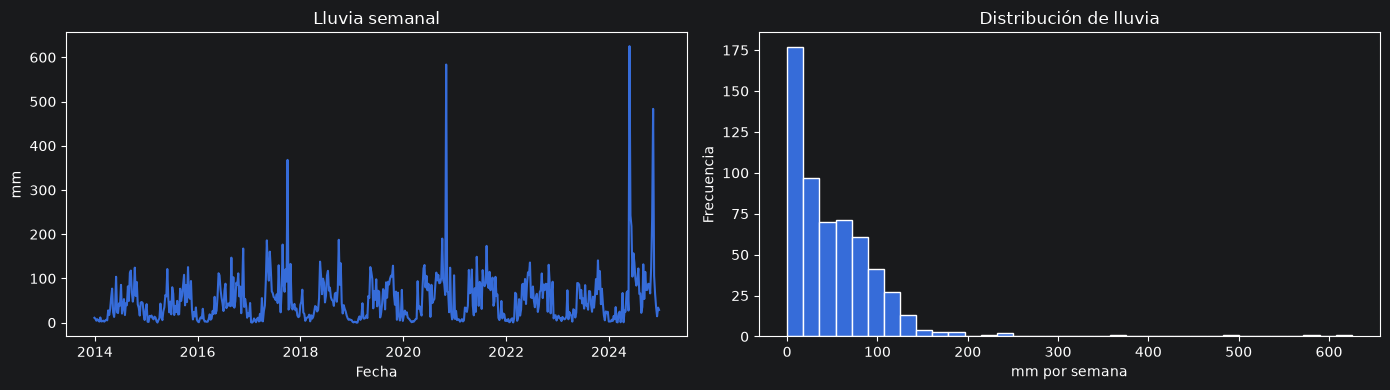

In [19]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
ejes[0].plot(datos["fecha_inicio_semana"], datos["lluvia_mm"])
ejes[0].set(title="Lluvia semanal", xlabel="Fecha", ylabel="mm")
ejes[1].hist(datos["lluvia_mm"], bins=35, edgecolor="white")
ejes[1].set(title="Distribución de lluvia", xlabel="mm por semana", ylabel="Frecuencia")
plt.tight_layout()
plt.show()

## 20. Temperaturas máxima y mínima

Se observan las variaciones semanales de las temperaturas y sus rangos, en relación con el ciclo climático.

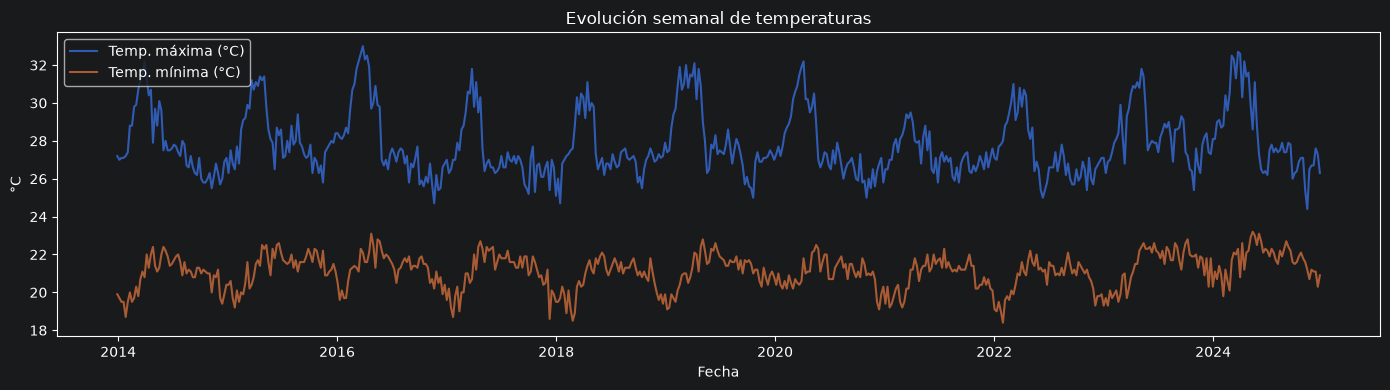

In [20]:
plt.figure(figsize=(14, 4))
plt.plot(datos["fecha_inicio_semana"], datos["temp_max_c"], label="Temp. máxima (°C)", alpha=0.8)
plt.plot(datos["fecha_inicio_semana"], datos["temp_min_c"], label="Temp. mínima (°C)", alpha=0.8)
plt.title("Evolución semanal de temperaturas")
plt.xlabel("Fecha")
plt.ylabel("°C")
plt.legend()
plt.tight_layout()
plt.show()

## 21. Evolución de la humedad relativa

Se describe la humedad relativa promedio por semana y su dispersión.

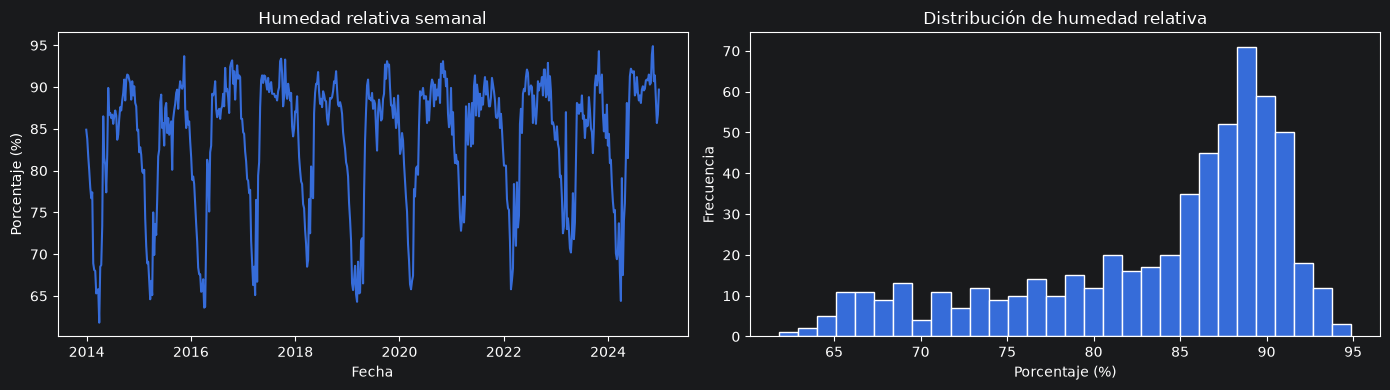

In [21]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
ejes[0].plot(datos["fecha_inicio_semana"], datos["humedad_rel_pct"])
ejes[0].set(title="Humedad relativa semanal", xlabel="Fecha", ylabel="Porcentaje (%)")
ejes[1].hist(datos["humedad_rel_pct"], bins=30, edgecolor="white")
ejes[1].set(title="Distribución de humedad relativa", xlabel="Porcentaje (%)", ylabel="Frecuencia")
plt.tight_layout()
plt.show()

## 22. Análisis de eventos climáticos extremos

Se enumeran las semanas más lluviosas y las que registraron más casos, sin asumir causalidad. El material del profesor menciona Nate (2017), Eta (2020) y Sara (2024) como contexto para revisar valores extremos.

In [22]:
print("12 semanas con mayor lluvia:")
display(datos.nlargest(12, "lluvia_mm")[["fecha_inicio_semana", "anio", "semana_epi", "lluvia_mm", "casos_dengue"]])
print("12 semanas con mayor cantidad de casos:")
display(datos.nlargest(12, "casos_dengue")[["fecha_inicio_semana", "anio", "semana_epi", "casos_dengue", "lluvia_mm"]])

12 semanas con mayor lluvia:


,fecha_inicio_semana,anio,semana_epi,lluvia_mm,casos_dengue
543,2024-05-26,2024,22,625.20,489
357,2020-11-01,2020,45,583.60,106
567,2024-11-10,2024,46,483.40,387
196,2017-10-01,2017,40,368.00,98
544,2024-06-02,2024,23,242.40,636
566,2024-11-03,2024,45,236.40,494
545,2024-06-09,2024,24,218.20,648
353,2020-10-04,2020,41,190.10,103
248,2018-09-30,2018,40,187.40,53
175,2017-05-07,2017,19,186.10,82


12 semanas con mayor cantidad de casos:


,fecha_inicio_semana,anio,semana_epi,casos_dengue,lluvia_mm
515,2023-11-12,2023,46,1749,76.70
514,2023-11-05,2023,45,1647,41.80
509,2023-10-01,2023,40,1539,98.60
511,2023-10-15,2023,42,1526,140.80
516,2023-11-19,2023,47,1520,43.50
510,2023-10-08,2023,41,1486,64.60
517,2023-11-26,2023,48,1473,17.10
513,2023-10-29,2023,44,1471,116.50
512,2023-10-22,2023,43,1402,75.60
518,2023-12-03,2023,49,1388,5.40


## 23. Matriz de correlaciones

Se calculan las correlaciones de Pearson entre casos y variables climáticas, tanto con casos originales como con `log1p(casos)`. Una correlación contemporánea no sustituye el análisis de rezagos.

,casos_dengue,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
casos_dengue,1.00,0.15,-0.15,0.34,0.32
lluvia_mm,0.15,1.00,-0.42,0.36,0.52
temp_max_c,-0.15,-0.42,1.00,0.10,-0.88
temp_min_c,0.34,0.36,0.10,1.00,0.30
humedad_rel_pct,0.32,0.52,-0.88,0.30,1.00


Correlación contemporánea con log(1 + casos):


log_casos          1.00
lluvia_mm          0.22
temp_max_c        -0.21
temp_min_c         0.43
humedad_rel_pct    0.42
Name: log_casos, dtype: float64

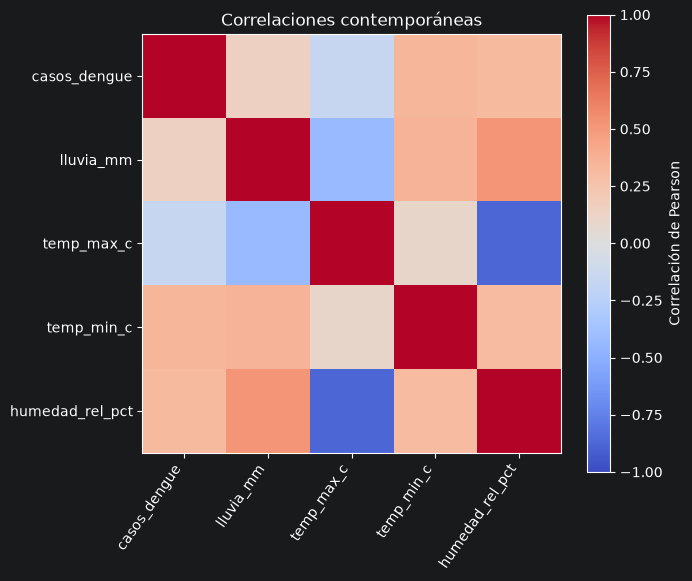

In [23]:
variables_correlacion = ["casos_dengue", "lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]
correlaciones = datos[variables_correlacion].corr()
datos["log_casos"] = np.log1p(datos["casos_dengue"])
correlaciones_log = datos[["log_casos", "lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]].corr()
display(correlaciones.round(3))
print("Correlación contemporánea con log(1 + casos):")
display(correlaciones_log["log_casos"].round(3))

plt.figure(figsize=(7, 6))
plt.imshow(correlaciones, vmin=-1, vmax=1, cmap="coolwarm")
plt.xticks(range(len(correlaciones.columns)), correlaciones.columns, rotation=55, ha="right")
plt.yticks(range(len(correlaciones.index)), correlaciones.index)
plt.colorbar(label="Correlación de Pearson")
plt.title("Correlaciones contemporáneas")
plt.tight_layout()
plt.show()

## 24. Relación entre variables climáticas y casos

Se crean diagramas de dispersión para explorar asociaciones visuales. Se utiliza `log1p(casos)` para representar mejor años con brotes elevados.

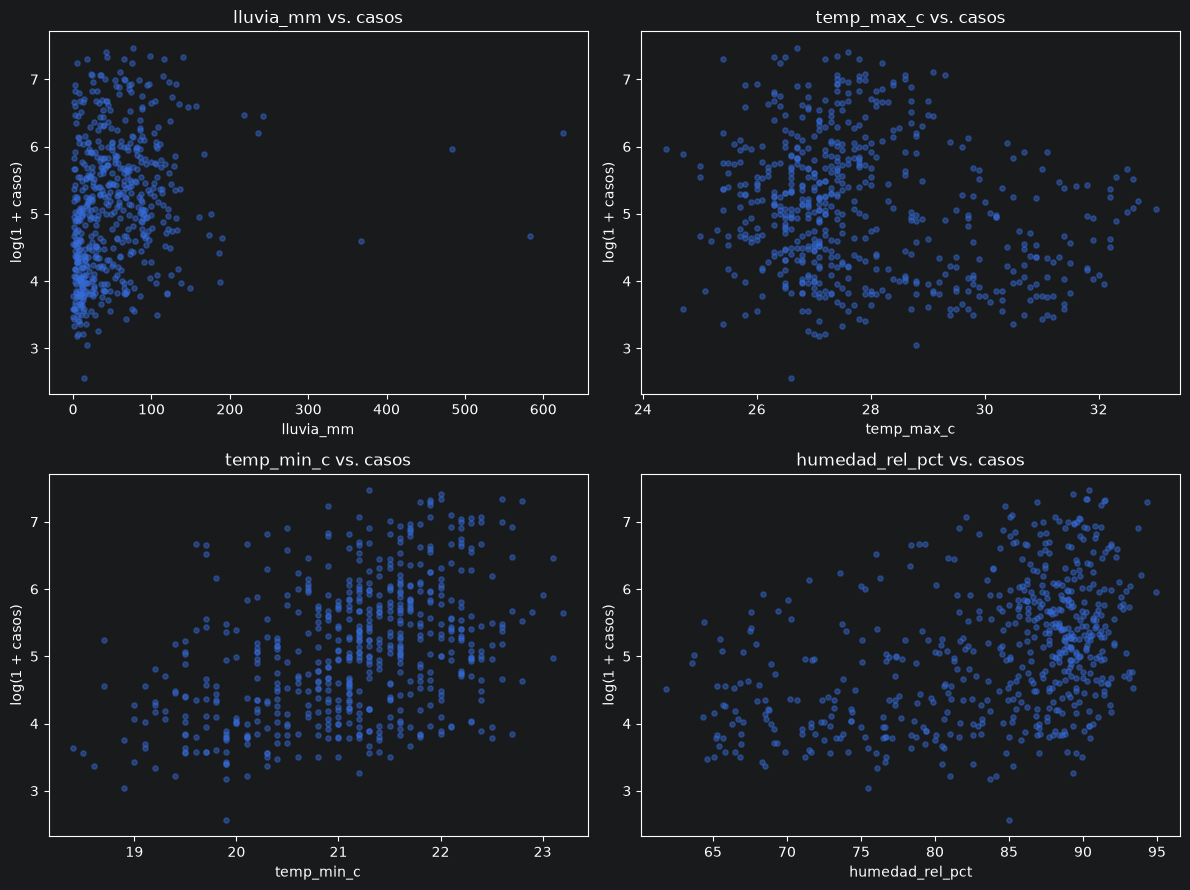

In [24]:
clima = ["lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]
fig, ejes = plt.subplots(2, 2, figsize=(12, 9))
for eje, variable in zip(ejes.flat, clima):
    eje.scatter(datos[variable], datos["log_casos"], alpha=0.45, s=14)
    eje.set(xlabel=variable, ylabel="log(1 + casos)", title=f"{variable} vs. casos")
plt.tight_layout()
plt.show()

## 25. Análisis de rezagos climáticos (lags 0–12)

Se compara el clima de **semanas anteriores** con los casos de la semana actual. `shift(lag)` utiliza valores disponibles antes del objetivo y evita introducir clima futuro como entrada. La correlación no implica causalidad.

,Variable,Rezago (semanas),Correlación
40,humedad_rel_pct,1,0.42
3,lluvia_mm,3,0.26
25,temp_max_c,12,0.41
34,temp_min_c,8,0.65


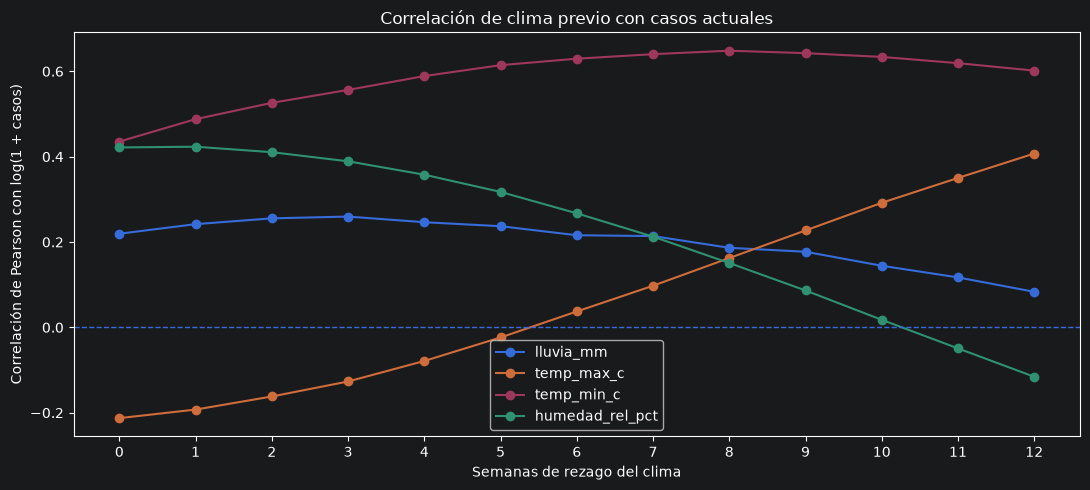

In [25]:
lista_rezagos = []
for variable in clima:
    for lag in range(13):
        serie_clima_previa = datos[variable].shift(lag)
        r = serie_clima_previa.corr(datos["log_casos"])
        lista_rezagos.append({"Variable": variable, "Rezago (semanas)": lag, "Correlación": r})
df_rezagos = pd.DataFrame(lista_rezagos)
mejores_rezagos = (df_rezagos.assign(Abs_r=lambda t: t["Correlación"].abs())
                   .sort_values("Abs_r", ascending=False)
                   .drop_duplicates("Variable")
                   .drop(columns="Abs_r")
                   .sort_values("Variable"))
display(mejores_rezagos.round(3))

plt.figure(figsize=(11, 5))
for variable, grupo in df_rezagos.groupby("Variable", sort=False):
    plt.plot(grupo["Rezago (semanas)"], grupo["Correlación"], marker="o", label=variable)
plt.axhline(0, linestyle="--", linewidth=1)
plt.xticks(range(13))
plt.xlabel("Semanas de rezago del clima")
plt.ylabel("Correlación de Pearson con log(1 + casos)")
plt.title("Correlación de clima previo con casos actuales")
plt.legend()
plt.tight_layout()
plt.show()

## 26. Análisis de autocorrelación de casos

Se estudia cuánto se relacionan los casos actuales con los de semanas anteriores, incluyendo rezagos de hasta 52 semanas (aproximadamente un año).

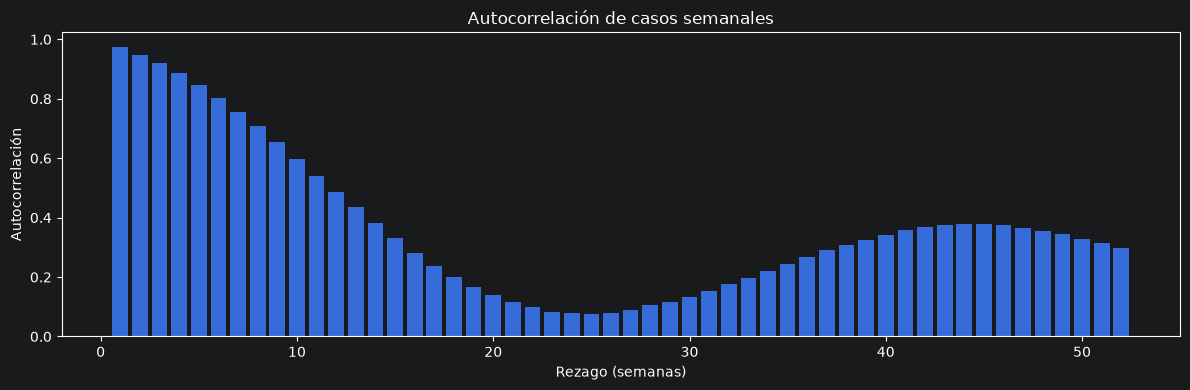

,Rezago (semanas),Autocorrelación
0,1,0.97
1,2,0.95
3,4,0.89
11,12,0.49
25,26,0.08
51,52,0.30


In [26]:
autocorr_resultados = pd.DataFrame({
    "Rezago (semanas)": range(1, 53),
    "Autocorrelación": [datos["casos_dengue"].autocorr(lag=i) for i in range(1, 53)],
})
plt.figure(figsize=(12, 4))
plt.bar(autocorr_resultados["Rezago (semanas)"], autocorr_resultados["Autocorrelación"])
plt.title("Autocorrelación de casos semanales")
plt.xlabel("Rezago (semanas)")
plt.ylabel("Autocorrelación")
plt.tight_layout()
plt.show()
display(autocorr_resultados.loc[autocorr_resultados["Rezago (semanas)"].isin([1, 2, 4, 12, 26, 52])].round(3))

## 27. Análisis de tendencias y cambios entre períodos

Se comparan los casos por año y los niveles en tres períodos históricos, para observar posibles cambios de distribución a lo largo del tiempo.

,count,mean,median,std,max
periodo,,,,,
2014–2018,261,230.46,145.00,229.44,1000
2019–2021,157,156.88,131.00,110.03,468
2022–2024,156,444.83,256.00,441.81,1749


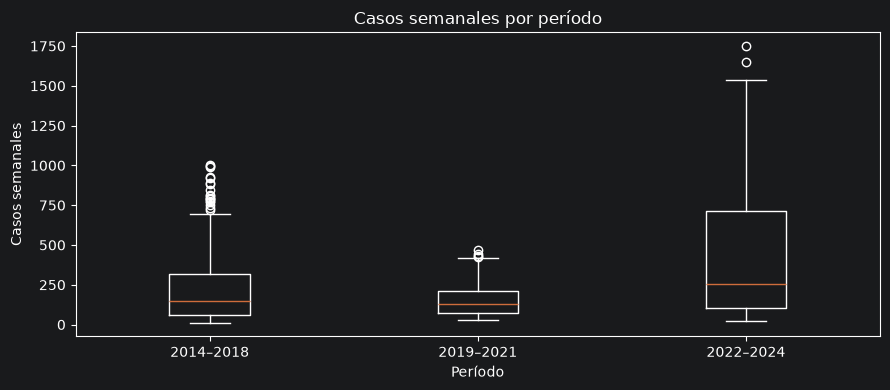

In [27]:
datos["periodo"] = pd.cut(datos["anio"], bins=[2013, 2018, 2021, 2024],
                          labels=["2014–2018", "2019–2021", "2022–2024"])
comparacion_periodos = datos.groupby("periodo", observed=True)["casos_dengue"].agg(["count", "mean", "median", "std", "max"])
display(comparacion_periodos.round(2))
fig, eje = plt.subplots(figsize=(9, 4))
grupos = [datos.loc[datos["periodo"] == etiqueta, "casos_dengue"] for etiqueta in datos["periodo"].cat.categories]
eje.boxplot(grupos, tick_labels=list(datos["periodo"].cat.categories))
eje.set(title="Casos semanales por período", xlabel="Período", ylabel="Casos semanales")
plt.tight_layout()
plt.show()

## 28. Ventanas temporales: 26 semanas de entrada y 4 de salida

Se verifica cuántos ejemplos podrían construirse para la LSTM usando 26 semanas anteriores de casos y clima, y cuatro semanas futuras de casos como **objetivo**. No se hace entrenamiento ni escalado en este EDA.

In [28]:
ventana_entrada = 26
horizonte = 4
features_modelo = ["casos_dengue", "lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]
valores_entrada = datos[features_modelo].to_numpy()
valores_objetivo = datos["casos_dengue"].to_numpy()
X_ventanas = np.array([
    valores_entrada[i:i + ventana_entrada]
    for i in range(len(datos) - ventana_entrada - horizonte + 1)
])
y_ventanas = np.array([
    valores_objetivo[i + ventana_entrada:i + ventana_entrada + horizonte]
    for i in range(len(datos) - ventana_entrada - horizonte + 1)
])
print("Ventanas disponibles:", len(X_ventanas))
print("Forma X (ejemplos, semanas, variables):", X_ventanas.shape)
print("Forma y (ejemplos, 4 semanas futuras):", y_ventanas.shape)
print("Primer intervalo de entrada:", datos.loc[0, "fecha_inicio_semana"].date(), "a", datos.loc[25, "fecha_inicio_semana"].date())
print("Primer intervalo objetivo:", datos.loc[26, "fecha_inicio_semana"].date(), "a", datos.loc[29, "fecha_inicio_semana"].date())
print("Primer objetivo (casos reales, no predicciones):", y_ventanas[0].tolist())

Ventanas disponibles: 545
Forma X (ejemplos, semanas, variables): (545, 26, 5)
Forma y (ejemplos, 4 semanas futuras): (545, 4)
Primer intervalo de entrada: 2013-12-29 a 2014-06-22
Primer intervalo objetivo: 2014-06-29 a 2014-07-20
Primer objetivo (casos reales, no predicciones): [332, 342, 387, 322]


## 29. Comparación exploratoria con baseline estacional

Se compara cada semana con **la misma semana epidemiológica del año anterior**. Se usa la clave `(anio, semana_epi)` en lugar de restar 52 filas, porque existen años de 53 semanas. Se calculan MAE y RMSE del baseline, no de la LSTM.

,Período,Semanas evaluadas,MAE,RMSE
0,Todas las semanas disponibles,520,227.67,358.71
1,2023–2024,104,447.50,630.70


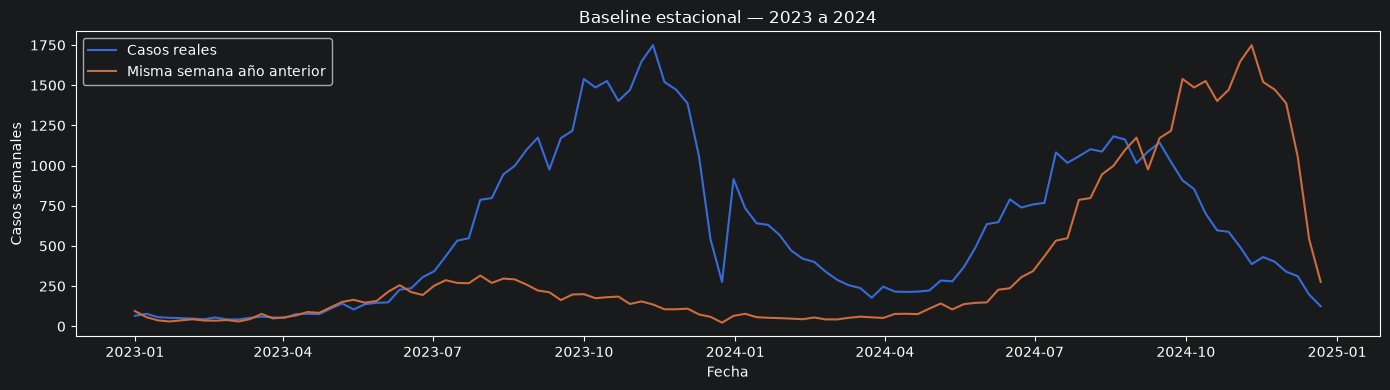

In [29]:
comparacion_baseline = datos[["fecha_inicio_semana", "anio", "semana_epi", "casos_dengue"]].copy()
previo = datos[["anio", "semana_epi", "casos_dengue"]].copy()
previo["anio"] = previo["anio"] + 1
previo = previo.rename(columns={"casos_dengue": "baseline_anio_anterior"})
comparacion_baseline = comparacion_baseline.merge(previo, on=["anio", "semana_epi"], how="left", validate="one_to_one")
comparacion_baseline["error"] = comparacion_baseline["casos_dengue"] - comparacion_baseline["baseline_anio_anterior"]
con_baseline = comparacion_baseline.dropna(subset=["baseline_anio_anterior"]).copy()

def metricas_baseline(tabla):
    error = tabla["error"].to_numpy()
    return {"Semanas evaluadas": len(error), "MAE": np.abs(error).mean(), "RMSE": np.sqrt(np.mean(error ** 2))}

resultados_baseline = pd.DataFrame([
    {"Período": "Todas las semanas disponibles", **metricas_baseline(con_baseline)},
    {"Período": "2023–2024", **metricas_baseline(con_baseline[con_baseline["anio"].between(2023, 2024)])},
])
display(resultados_baseline.round(2))
ultimas = con_baseline[con_baseline["anio"].between(2023, 2024)]
plt.figure(figsize=(14, 4))
plt.plot(ultimas["fecha_inicio_semana"], ultimas["casos_dengue"], label="Casos reales")
plt.plot(ultimas["fecha_inicio_semana"], ultimas["baseline_anio_anterior"], label="Misma semana año anterior")
plt.title("Baseline estacional — 2023 a 2024")
plt.xlabel("Fecha")
plt.ylabel("Casos semanales")
plt.legend()
plt.tight_layout()
plt.show()

## 30. Revisión de partición temporal para la evaluación

Se muestra una posible división cronológica, **solo para explorar**. Evita mezclar aleatoriamente semanas futuras con pasadas y permite comprobar el cambio de distribución durante los brotes.

In [30]:
def asignar_periodo(anio):
    if anio <= 2021:
        return "Entrenamiento (2014–2021)"
    if anio == 2022:
        return "Validación (2022)"
    return "Prueba (2023–2024)"

datos["particion_sugerida"] = datos["anio"].map(asignar_periodo)
tabla_particiones = datos.groupby("particion_sugerida")["casos_dengue"].agg(
    semanas="count", media="mean", mediana="median", maximo="max")
display(tabla_particiones.round(2))
print("Nota: el escalado y cualquier ajuste de transformaciones se deben aprender solo del entrenamiento.")

,semanas,media,mediana,maximo
particion_sugerida,,,,
Entrenamiento (2014–2021),418,202.82,139.00,1000
Prueba (2023–2024),104,595.27,480.50,1749
Validación (2022),52,143.94,143.00,316


Nota: el escalado y cualquier ajuste de transformaciones se deben aprender solo del entrenamiento.


## 31. Casos reales acumulados durante cuatro semanas futuras

Se calcula un ejemplo de la variable objetivo a cuatro semanas usando casos **observados**. No representa una predicción. Las últimas cuatro semanas no tienen objetivo completo dentro del CSV.

In [31]:
componentes_futuros = pd.concat(
    [datos["casos_dengue"].shift(-paso).rename(f"semana_futura_{paso}") for paso in range(1, 5)], axis=1
)
datos["casos_4_semanas_siguientes"] = componentes_futuros.sum(axis=1, min_count=4)
columnas_muestra = ["fecha_inicio_semana", "anio", "semana_epi", "casos_dengue", "casos_4_semanas_siguientes"]
display(datos[columnas_muestra].iloc[24:32])
print("Semanas sin objetivo futuro completo:", int(datos["casos_4_semanas_siguientes"].isna().sum()))

,fecha_inicio_semana,anio,semana_epi,casos_dengue,casos_4_semanas_siguientes
24,2014-06-15,2014,25,260,1365.00
25,2014-06-22,2014,26,304,1383.00
26,2014-06-29,2014,27,332,1406.00
27,2014-07-06,2014,28,342,1434.00
28,2014-07-13,2014,29,387,1352.00
29,2014-07-20,2014,30,322,1367.00
30,2014-07-27,2014,31,355,1366.00
31,2014-08-03,2014,32,370,1380.00


Semanas sin objetivo futuro completo: 4


## 32. Resumen automático del análisis

Se recopilan los principales indicadores de calidad, cobertura y patrones temporales del dataset. **Este apartado solo resume observaciones; no redacta conclusiones.**

In [32]:
mejor_temp_min = df_rezagos.loc[df_rezagos["Variable"] == "temp_min_c"].assign(
    abs_r=lambda tabla: tabla["Correlación"].abs()
).sort_values("abs_r", ascending=False).iloc[0]
pico_maximo = datos.loc[datos["casos_dengue"].idxmax()]
anio_mayor = casos_anuales.loc[casos_anuales["Casos anuales"].idxmax()]

resumen = {
    "Filas (semanas)": len(datos),
    "Columnas originales": columnas,
    "Años epidemiológicos": datos["anio"].nunique(),
    "Año epidemiológico inicial": int(datos["anio"].min()),
    "Año epidemiológico final": int(datos["anio"].max()),
    "Fechas semanales ausentes": len(fechas_faltantes),
    "Valores faltantes originales": int(faltantes.sum()),
    "Filas duplicadas": int(repetidos_fila),
    "Semanas duplicadas": int(repetidos_semana),
    "Casos acumulados en toda la serie": int(datos["casos_dengue"].sum()),
    "Casos semanales promedio": round(datos["casos_dengue"].mean(), 2),
    "Casos semanales máximos": int(pico_maximo["casos_dengue"]),
    "Semana del máximo": f"{int(pico_maximo['anio'])} / semana {int(pico_maximo['semana_epi'])}",
    "Año con más casos": int(anio_mayor["anio"]),
    "Casos del año con más casos": int(anio_mayor["Casos anuales"]),
    "Semanas atípicas en casos (IQR)": int(df_atipicos.loc[df_atipicos["Variable"] == "casos_dengue", "Atípicos IQR"].iloc[0]),
    "Rezago más correlacionado de temp_min (semanas)": int(mejor_temp_min["Rezago (semanas)"]),
    "Correlación temp_min / log(1+casos) en ese rezago": round(float(mejor_temp_min["Correlación"]), 3),
    "Ventanas 26→4 posibles": len(X_ventanas),
    "Baseline estacional MAE (todas las semanas disponibles)": round(float(resultados_baseline.iloc[0]["MAE"]), 2),
    "Baseline estacional RMSE (todas las semanas disponibles)": round(float(resultados_baseline.iloc[0]["RMSE"]), 2),
}
resumen_eda = pd.DataFrame(resumen.items(), columns=["Indicador", "Resultado"])
display(resumen_eda)
print("\nPrincipales correlaciones por variable (lags 0–12):")
display(mejores_rezagos.round(3))
print("\nDistribución de semanas por partición temporal sugerida:")
display(tabla_particiones.round(2))
print("\nEste resumen no equivale al desempeño de un modelo entrenado.")

,Indicador,Resultado
0,Filas (semanas),574
1,Columnas originales,12
2,Años epidemiológicos,11
3,Año epidemiológico inicial,2014
4,Año epidemiológico final,2024
5,Fechas semanales ausentes,0
6,Valores faltantes originales,0
7,Filas duplicadas,0
8,Semanas duplicadas,0
9,Casos acumulados en toda la serie,154172



Principales correlaciones por variable (lags 0–12):


,Variable,Rezago (semanas),Correlación
40,humedad_rel_pct,1,0.42
3,lluvia_mm,3,0.26
25,temp_max_c,12,0.41
34,temp_min_c,8,0.65



Distribución de semanas por partición temporal sugerida:


,semanas,media,mediana,maximo
particion_sugerida,,,,
Entrenamiento (2014–2021),418,202.82,139.00,1000
Prueba (2023–2024),104,595.27,480.50,1749
Validación (2022),52,143.94,143.00,316



Este resumen no equivale al desempeño de un modelo entrenado.



## 33. Conclusiones generales del EDA

El análisis exploratorio del dataset `vectoria_dengue_nacional_real.csv` permitió estudiar el comportamiento histórico de los casos de dengue en Costa Rica entre 2014 y 2024, así como su relación con las condiciones climáticas.

Se analizaron las tendencias temporales, los períodos epidémicos, la estacionalidad, las correlaciones climáticas y los rezagos temporales, con el objetivo de identificar patrones relevantes para el posterior entrenamiento de los modelos SimpleRNN y LSTM del proyecto VectorIA.

### 33.1. Principales hallazgos

1. **Cantidad de registros:** se analizaron 574 semanas correspondientes a 11 años epidemiológicos, desde 2014 hasta 2024. El dataset contiene 12 columnas originales y un total acumulado de 154.172 casos de dengue.

2. **Calidad e integridad de los datos:** no se identificaron valores faltantes, registros duplicados, semanas duplicadas ni fechas semanales ausentes. Esto representa una ventaja para la preparación de las series temporales.

3. **Distribución de casos:** el promedio semanal fue de 268,59 casos. Sin embargo, se observaron diferencias importantes entre períodos, especialmente durante los años con mayor actividad epidémica.

4. **Valores máximos:** el mayor registro semanal fue de 1.749 casos, correspondiente a la semana epidemiológica 46 de 2023. Esto evidencia un período de transmisión considerablemente superior al comportamiento habitual.

5. **Año con más casos:** 2024 registró la mayor cantidad anual, con 31.259 casos. Este resultado confirma la elevada actividad del dengue durante los últimos años del período analizado.

6. **Valores atípicos:** mediante el método del rango intercuartílico (IQR), se identificaron 57 semanas con cantidades atípicas de casos. Estos valores pueden estar asociados con brotes epidémicos y no deben considerarse automáticamente errores del dataset.

7. **Comportamiento temporal:** los gráficos muestran variaciones considerables en la cantidad de casos entre años. Destacan los incrementos de 2023 y 2024, que presentan niveles superiores a los observados en varios períodos anteriores.

8. **Estacionalidad:** se observaron fluctuaciones de casos a lo largo del año, con períodos de mayor incidencia. Sin embargo, la intensidad y el momento de los picos no son idénticos todos los años.

9. **Variables climáticas:** se analizaron lluvia, temperatura máxima, temperatura mínima y humedad relativa. Estas variables presentan relaciones diferentes con los casos de dengue y podrían aportar información relevante para el pronóstico.

10. **Temperatura mínima:** presentó la correlación positiva más elevada entre las variables climáticas analizadas, con un coeficiente de Pearson de aproximadamente 0,65 utilizando un rezago de 8 semanas respecto a log(1 + casos). Esto sugiere una asociación importante entre la temperatura mínima previa y los casos posteriores.

11. **Temperatura máxima:** presentó una correlación aproximada de 0,41 con un rezago de 12 semanas. Su relación con los casos cambia según el intervalo temporal considerado.

12. **Humedad relativa:** alcanzó una correlación aproximada de 0,42 con un rezago de 1 semana, mostrando una asociación positiva moderada en ese intervalo.

13. **Precipitación:** la lluvia presentó su mayor correlación positiva aproximada de 0,26 con un rezago de 3 semanas. Esta relación es más débil que la observada para la temperatura mínima.

14. **Importancia de los rezagos:** los resultados muestran que las relaciones entre clima y dengue cambian cuando se consideran condiciones meteorológicas de semanas anteriores. Por lo tanto, las variables climáticas rezagadas representan características potencialmente útiles para la LSTM. Estas correlaciones no demuestran por sí solas relaciones causales.

15. **Distribución por períodos:** se identificaron diferencias importantes entre las particiones temporales propuestas:

    - Entrenamiento (2014–2021): 418 semanas, con promedio de 202,82 casos semanales.
    - Validación (2022): 52 semanas, con promedio de 143,94 casos semanales.
    - Prueba (2023–2024): 104 semanas, con promedio de 595,27 casos semanales.

    Esto evidencia que el período de prueba presenta una distribución de casos considerablemente diferente a la de entrenamiento y validación.

16. **Baseline estacional:** el método de utilizar los casos de la misma semana del año anterior obtuvo un MAE de 227,67 y un RMSE de 358,71, calculados sobre las semanas disponibles para esta comparación.

17. **Limitaciones del baseline:** los gráficos muestran diferencias importantes entre los casos reales y los valores del año anterior, especialmente durante los brotes de 2023 y 2024. Esto indica que repetir el comportamiento del año previo no siempre permite anticipar correctamente los cambios de intensidad epidémica.

18. **Ventanas temporales:** se identificaron 545 ventanas posibles utilizando 26 semanas de entrada para predecir las siguientes 4 semanas. Esto confirma la posibilidad de preparar secuencias supervisadas para el modelo LSTM propuesto.

### 33.2. Recomendaciones para el entrenamiento

- **Mantener el orden temporal:** realizar la separación de entrenamiento, validación y prueba respetando la secuencia cronológica de las semanas.

- **Evitar fugas de información:** ajustar los métodos de escalado únicamente con los datos de entrenamiento y utilizar exclusivamente información disponible hasta el momento de cada predicción.

- **Incorporar rezagos climáticos:** evaluar especialmente la temperatura mínima con rezagos cercanos a 8 semanas, además de otras combinaciones temporales de lluvia, humedad y temperatura máxima.

- **Comparar diferentes rezagos:** no limitar la selección de variables únicamente a los rezagos que presentaron mayores correlaciones individuales, sino comprobar su utilidad mediante la validación del modelo.

- **Conservar los períodos epidémicos:** evitar eliminar automáticamente las 57 semanas atípicas, debido a que podrían representar brotes reales relevantes para el aprendizaje del modelo.

- **Analizar el comportamiento estacional:** considerar variables de calendario, como semana epidemiológica y año, para representar posibles patrones temporales.

- **Utilizar ventanas de 26 semanas:** preparar las secuencias de entrada y las salidas de cuatro semanas propuestas para el modelo, verificando que las ventanas no introduzcan información futura en el entrenamiento.

- **Comparar SimpleRNN y LSTM:** evaluar ambos modelos utilizando RMSE y MAE sobre el mismo conjunto de prueba.

- **Superar el baseline estacional:** utilizar los errores del método estacional como referencia para determinar si los modelos neuronales realmente aportan una mejora predictiva. La comparación debe realizarse sobre las mismas semanas de evaluación.

- **Evaluar los años epidémicos:** prestar especial atención al rendimiento durante 2023 y 2024, debido a que presentan una cantidad de casos significativamente superior a la de períodos anteriores.

- **Considerar la transformación de casos:** evaluar transformaciones como log(1 + casos) si ayudan a manejar la asimetría de la distribución, recuperando posteriormente la escala original para interpretar las predicciones.

- **Evaluar el comportamiento fuera de muestra:** comprobar la capacidad de generalización del modelo ante períodos con características diferentes a las utilizadas durante el entrenamiento.

- **Preparar la predicción de cuatro semanas:** mantener como objetivo la estimación semanal de casos de dengue para las cuatro semanas posteriores a la fecha de referencia.

- **Considerar las proyecciones futuras:** para ampliar el sistema a consultas de 2026, se necesitarán datos climáticos reales o estimados y una estrategia de pronóstico que permita avanzar desde el último período disponible. Las predicciones intermedias deberán distinguirse de los datos observados.

### 33.3. Conclusión final

El dataset nacional de dengue y clima presenta características favorables para el desarrollo de modelos de predicción temporal, debido a su cobertura de 574 semanas, la disponibilidad de variables meteorológicas y la ausencia de valores faltantes o registros duplicados.

El análisis identificó una variabilidad considerable en la cantidad de casos de dengue entre años, destacando los brotes de 2023 y 2024. El registro máximo de 1.749 casos semanales y la identificación de 57 semanas atípicas evidencian la importancia de conservar y analizar los períodos epidémicos durante el entrenamiento.

Uno de los hallazgos más relevantes fue la relación entre las condiciones climáticas previas y los casos de dengue. La temperatura mínima presentó la mayor correlación observada, con un valor aproximado de 0,65 y un rezago de 8 semanas. Por su parte, la humedad, la temperatura máxima y la lluvia mostraron asociaciones de diferente intensidad.

Estos resultados respaldan la conveniencia de incorporar variables climáticas rezagadas en los modelos de predicción. Sin embargo, las correlaciones exploratorias no garantizan que dichas variables mejoren el desempeño de una LSTM, por lo que deberán evaluarse durante el entrenamiento.

También se encontraron diferencias significativas entre los períodos de entrenamiento y prueba. Mientras que el período de 2014 a 2021 presentó un promedio de 202,82 casos semanales, los años 2023 y 2024 alcanzaron un promedio de 595,27. Esta diferencia representa un desafío para la generalización del modelo.

La evaluación del baseline estacional produjo un MAE de 227,67 y un RMSE de 358,71. Estos resultados servirán como punto de referencia para comprobar si SimpleRNN y LSTM logran ofrecer predicciones más precisas.

Finalmente, se determinó que es posible construir 545 ventanas temporales de 26 semanas de entrada y 4 semanas de salida sobre la serie disponible. Esto proporciona una estructura inicial para preparar los datos de entrenamiento.

En conclusión, el dataset es adecuado para desarrollar y evaluar modelos de predicción de casos semanales de dengue. Los principales aspectos que deberán considerarse son los rezagos climáticos, la estacionalidad, los períodos epidémicos, las diferencias entre conjuntos temporales y la prevención de fugas de información.

El rendimiento predictivo de los modelos y su capacidad para anticipar nuevos brotes deberán determinarse posteriormente mediante el entrenamiento y la evaluación de SimpleRNN y LSTM.
